# 01 · Exploración de datos (EDA)

**Pregunta de negocio (PSet 1):** pronosticar las ventas (comprobantes) de cada hora abierta de la matriz para la semana siguiente, y con ese pronóstico decidir qué horas necesitan un vendedor de refuerzo (carga ≥ 8 ventas por vendedor presente).

**Datos:** la OBT del PSet 2 (`PSET2.OBT.OBT_SALES_HOURLY`), filtrada a la matriz. Una fila = una hora abierta. Se usa un snapshot congelado (`src/datos.py`) cuyo hash queda registrado en MLflow.

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="mlflow")   # avisos de esquema de MLflow
import os, logging
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
os.environ.setdefault("MLFLOW_SUPPRESS_PRINTING_URL_TO_STDOUT", "1")
logging.getLogger("mlflow").setLevel(logging.ERROR)   # avisos repetidos de serialización/entorno
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src.datos import cargar_obt
from src.pipeline import TARGET, FUGA, UMBRAL_CARGA
from src import estilo
estilo.aplicar()
pd.set_option("display.width", 140, "display.max_columns", 40)

snap = cargar_obt()
df = snap.datos
print(f"Origen: {snap.tabla_origen} · corte: {snap.fecha_corte} · hash: {snap.hash[:16]}…")
print(f"Filas: {len(df)} · columnas: {df.shape[1]} · fechas: {df.hour_date.min():%Y-%m-%d} a {df.hour_date.max():%Y-%m-%d}")

Origen: PSET2.OBT.OBT_SALES_HOURLY · corte: 2026-11-07 · hash: d40705c0073c3866…
Filas: 855 · columnas: 30 · fechas: 2026-08-20 a 2026-11-07


## 1. Tamaño, tipos y valores faltantes

In [2]:
resumen = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "faltantes": df.isna().sum(),
    "% faltantes": (df.isna().mean() * 100).round(1),
    "valores únicos": df.nunique(),
})
resumen

,tipo,faltantes,% faltantes,valores únicos
branch_id,int8,0,0.0,1
branch_name,str,0,0.0,1
experiment_role,str,0,0.0,1
hour_date,datetime64[ms],0,0.0,80
hour_of_day,int64,0,0.0,11
hour_label,str,0,0.0,11
day_part,str,0,0.0,3
iso_day_of_week,int64,0,0.0,7
day_name,str,0,0.0,7
is_weekend,bool,0,0.0,2


**Lectura.** Solo faltan valores en `holiday_name` (esperado: solo existe en feriados) y en los rezagos. Los rezagos faltan por **estructura**, no por error: la serie empieza el 20-08, así que `sales_lag_28d` no existe en las primeras 4 semanas.

In [3]:
faltan = (df.assign(semana=df.week_start_date.dt.strftime("%m-%d"))
            .groupby("semana")[["sales_lag_7d", "sales_lag_14d", "sales_lag_21d", "sales_lag_28d"]]
            .apply(lambda g: g.isna().mean().round(2)))
faltan

,sales_lag_7d,sales_lag_14d,sales_lag_21d,sales_lag_28d
semana,,,,
08-17,1.00,1.00,1.00,1.00
08-24,0.44,1.00,1.00,1.00
08-31,0.00,0.44,1.00,1.00
09-07,0.00,0.00,0.44,1.00
09-14,0.00,0.00,0.00,0.44
09-21,0.00,0.00,0.00,0.00
09-28,0.00,0.00,0.00,0.00
10-05,0.00,0.00,0.00,0.00
10-12,0.01,0.00,0.00,0.00


## 2. Estadística descriptiva

In [4]:
num = ["sales_count", "net_sales_amount", "units_sold", "staff_present", "sales_lag_7d",
       "sales_lag_14d", "sales_lag_28d", "sales_avg_4w_same_hour", "load_per_staff"]
desc = df[num].describe().T
desc["asimetría"] = df[num].skew()
desc["curtosis"] = df[num].kurt()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,asimetría,curtosis
sales_count,855.0,6.17,3.79,0.0,3.0,6.0,9.00,24.00,0.70,0.84
net_sales_amount,855.0,100.44,89.94,0.0,38.5,79.9,140.12,1019.77,2.45,14.78
units_sold,855.0,20.10,16.01,0.0,9.0,17.0,28.00,154.00,1.78,7.60
staff_present,855.0,1.47,0.50,1.0,1.0,1.0,2.00,2.00,0.10,-1.99
sales_lag_7d,779.0,6.16,3.82,0.0,3.0,6.0,9.00,24.00,0.73,0.92
sales_lag_14d,704.0,6.08,3.79,0.0,3.0,6.0,9.00,24.00,0.67,0.77
sales_lag_28d,554.0,6.15,3.88,0.0,3.0,6.0,9.00,24.00,0.60,0.48
sales_avg_4w_same_hour,780.0,6.13,3.11,0.0,4.0,6.0,8.00,17.00,0.33,-0.11
load_per_staff,855.0,4.56,3.34,0.0,2.5,4.0,6.00,24.00,1.53,3.70


## 3. Distribución del target (`sales_count`)

media 6.17 · mediana 6 · varianza 14.36 · var/media 2.33
asimetría 0.70 · horas con 0 ventas 4.3% · máximo 24


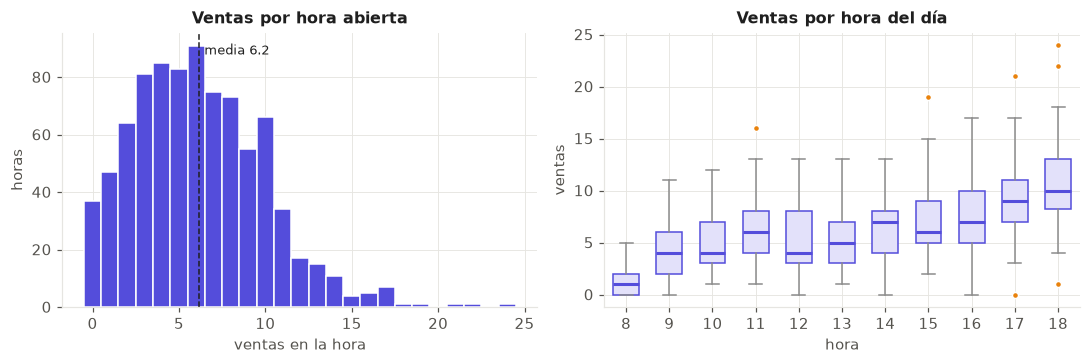

In [5]:
y = df[TARGET]
print(f"media {y.mean():.2f} · mediana {y.median():.0f} · varianza {y.var():.2f} · var/media {y.var()/y.mean():.2f}")
print(f"asimetría {stats.skew(y):.2f} · horas con 0 ventas {(y == 0).mean():.1%} · máximo {y.max()}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].hist(y, bins=np.arange(0, y.max() + 2) - 0.5, color=estilo.INDIGO, edgecolor="white", linewidth=1)
ax[0].axvline(y.mean(), color=estilo.TINTA, lw=1, ls="--")
ax[0].text(y.mean() + 0.3, ax[0].get_ylim()[1] * 0.92, f"media {y.mean():.1f}", fontsize=8.5)
ax[0].set(title="Ventas por hora abierta", xlabel="ventas en la hora", ylabel="horas")
por_hora = [df.loc[df.hour_of_day == h, TARGET] for h in range(8, 19)]
ax[1].boxplot(por_hora, tick_labels=range(8, 19), patch_artist=True, widths=0.6,
              boxprops=dict(facecolor="#e3e1fa", edgecolor=estilo.INDIGO),
              medianprops=dict(color=estilo.INDIGO, lw=2), whiskerprops=dict(color=estilo.GRIS),
              capprops=dict(color=estilo.GRIS), flierprops=dict(marker="o", ms=4, mfc=estilo.AMBAR, mec="white"))
ax[1].set(title="Ventas por hora del día", xlabel="hora", ylabel="ventas")
fig.tight_layout(); estilo.guardar(fig, "eda_target"); plt.show()

**Lectura.** El target es un **conteo sobredisperso** (varianza ≈ 2,3 × la media) con cola a la derecha, y su nivel depende mucho de la hora: se triplica entre las 9:00 y las 18:00. Con un target así, el error cuadrático pesa demasiado los picos raros. Por eso la métrica técnica es **WAPE** (MAE relativo a la venta total), y en el tuning se prueban transformaciones del target (log1p y raíz).

## 4. Valores atípicos: IQR y Z-score

In [6]:
q1, q3 = y.quantile([0.25, 0.75]); iqr = q3 - q1
lim_iqr = q3 + 1.5 * iqr
z = np.abs(stats.zscore(y))
atipicos = df.assign(z=z.round(2)).loc[(y > lim_iqr) | (z >= 3),
    ["hour_date", "day_name", "hour_of_day", TARGET, "z", "staff_present", "is_holiday"]]
print(f"IQR: límite superior {lim_iqr:.1f} → {(y > lim_iqr).sum()} horas · Z ≥ 3 (> {y.mean() + 3*y.std():.1f}) → {(z >= 3).sum()} horas")
atipicos.sort_values(TARGET, ascending=False)

IQR: límite superior 18.0 → 4 horas · Z ≥ 3 (> 17.5) → 5 horas


,hour_date,day_name,hour_of_day,sales_count,z,staff_present,is_holiday
138,2026-09-01,tue,18,24,4.71,1,False
246,2026-09-11,fri,18,22,4.18,1,False
780,2026-10-31,sat,17,21,3.92,2,False
114,2026-08-30,sun,15,19,3.39,1,False
396,2026-09-25,fri,18,18,3.12,1,False


In [7]:
# Atípicos condicionados a la hora: un 12 a las 9:00 es raro; a las 18:00 no lo es.
g = df.groupby("hour_of_day")[TARGET]
z_hora = (y - g.transform("mean")) / g.transform("std")
print(f"Z ≥ 3 dentro de su hora: {(z_hora.abs() >= 3).sum()} de {len(df)}")
df.assign(z_hora=z_hora.round(2)).loc[z_hora.abs() >= 3, ["hour_date", "day_name", "hour_of_day", TARGET, "z_hora"]]

Z ≥ 3 dentro de su hora: 4 de 855


,hour_date,day_name,hour_of_day,sales_count,z_hora
114,2026-08-30,sun,15,19,3.92
138,2026-09-01,tue,18,24,3.07
485,2026-10-04,sun,11,16,3.11
780,2026-10-31,sat,17,21,3.67


**Decisión.** Los atípicos son **picos reales** (fin de mes, sábados, la hora de las 18:00), no errores de registro: la calidad de datos del PSet 2 ya concilió comprobantes contra el ERP. **No se eliminan ni se recortan.** Justamente son las horas que más importa no subestimar (son las que necesitan refuerzo). Por eso la métrica de negocio penaliza no detectar una hora sobrecargada.

## 5. Relación entre el target y las variables

In [8]:
candidatas = ["hour_of_day", "iso_day_of_week", "is_holiday", "is_last_open_hour", "staff_present",
              "sales_lag_7d", "sales_lag_14d", "sales_lag_21d", "sales_lag_28d", "sales_avg_4w_same_hour"]
datos_corr = df[candidatas + [TARGET]].astype(float)
spearman = datos_corr.corr(method="spearman")
pearson = datos_corr.corr(method="pearson")
comp = pd.DataFrame({"spearman": spearman[TARGET], "pearson": pearson[TARGET]}).drop(TARGET)
comp.sort_values("spearman", ascending=False).round(3)

,spearman,pearson
sales_avg_4w_same_hour,0.577,0.570
hour_of_day,0.570,0.570
sales_lag_7d,0.488,0.481
sales_lag_14d,0.488,0.484
sales_lag_21d,0.483,0.464
sales_lag_28d,0.431,0.424
is_last_open_hour,0.294,0.348
staff_present,0.181,0.147
iso_day_of_week,0.177,0.166
is_holiday,0.016,0.015


**Por qué Spearman.** (1) El target es un conteo asimétrico con atípicos, y Spearman trabaja con rangos, así que es robusto a ellos. (2) Varias relaciones son monótonas pero no lineales (la hora sube por tramos, con una caída al almuerzo). (3) No supone normalidad. Pearson se muestra solo como contraste: los dos coinciden, lo que indica que no hay relaciones dominadas por unos pocos puntos.

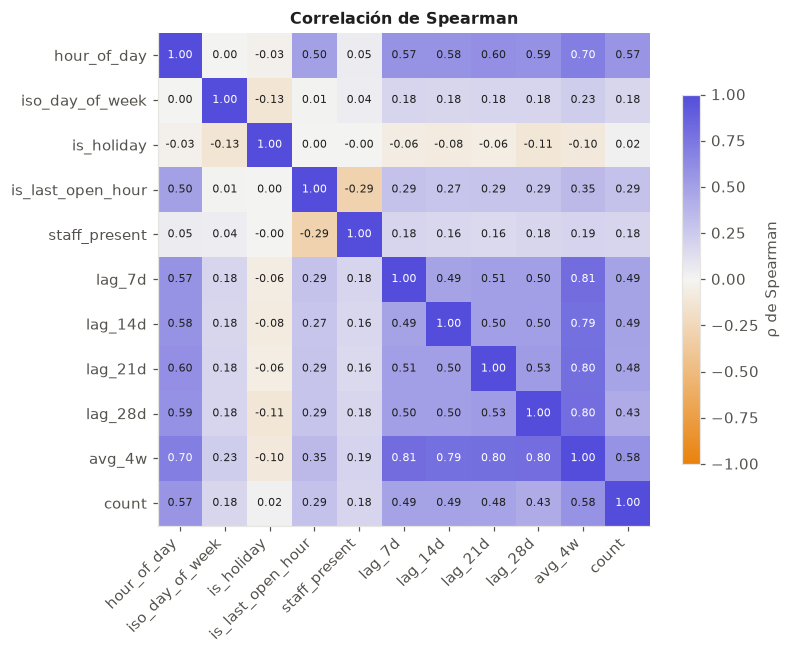

In [9]:
fig, ax = plt.subplots(figsize=(7.4, 6))
etiquetas = [c.replace("sales_", "").replace("_same_hour", "") for c in spearman.columns]
im = ax.imshow(spearman, cmap=estilo.DIVERGENTE, vmin=-1, vmax=1)
ax.set_xticks(range(len(etiquetas)), etiquetas, rotation=45, ha="right"); ax.set_yticks(range(len(etiquetas)), etiquetas)
ax.grid(False)
for i in range(len(etiquetas)):
    for j in range(len(etiquetas)):
        v = spearman.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > 0.6 else estilo.TINTA)
fig.colorbar(im, ax=ax, shrink=0.75, label="ρ de Spearman")
ax.set_title("Correlación de Spearman")
fig.tight_layout(); estilo.guardar(fig, "eda_correlacion"); plt.show()

**Lectura.** La hora (ρ ≈ 0,57) y el promedio de 4 semanas (ρ ≈ 0,58) son las variables más relacionadas con el target. Los cuatro rezagos están muy correlacionados entre sí (ρ entre 0,5 y 0,8), así que llevan información redundante: un modelo lineal necesita **regularización** (Ridge), y los árboles tienden a sobreajustar con tan pocas filas.

## 6. Patrones de calendario

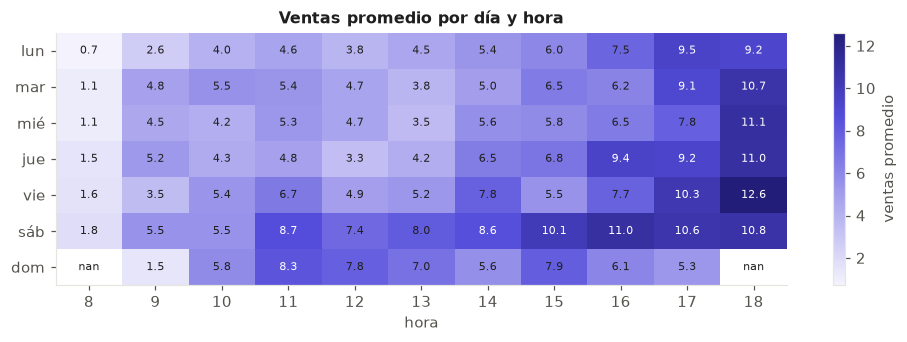

In [10]:
mapa = df.pivot_table(index="iso_day_of_week", columns="hour_of_day", values=TARGET, aggfunc="mean")
fig, ax = plt.subplots(figsize=(9, 3.2))
im = ax.imshow(mapa, cmap=estilo.SECUENCIAL, aspect="auto")
ax.set_yticks(range(7), ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]); ax.set_xticks(range(11), mapa.columns)
ax.grid(False)
for i in range(7):
    for j in range(11):
        v = mapa.iloc[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7.5, color="white" if v > 8 else estilo.TINTA)
fig.colorbar(im, ax=ax, label="ventas promedio")
ax.set(title="Ventas promedio por día y hora", xlabel="hora")
fig.tight_layout(); estilo.guardar(fig, "eda_dia_hora"); plt.show()

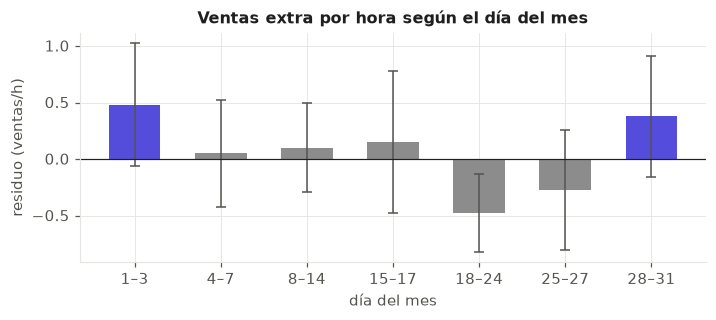

,mean,sem,count
hour_date,,,
1–3,0.48,0.28,95
4–7,0.05,0.24,128
8–14,0.10,0.20,149
15–17,0.15,0.32,66
18–24,-0.47,0.18,203
25–27,-0.27,0.27,95
28–31,0.38,0.27,119


In [11]:
# Efecto del día del mes: residuo frente al promedio de su misma hora y día de la semana.
res = df[TARGET] - df.groupby(["hour_of_day", "iso_day_of_week"])[TARGET].transform("mean")
tramos = pd.cut(df.hour_date.dt.day, [0, 3, 7, 14, 17, 24, 27, 31],
                labels=["1–3", "4–7", "8–14", "15–17", "18–24", "25–27", "28–31"])
efecto_mes = res.groupby(tramos, observed=True).agg(["mean", "sem", "count"])
efecto_dia_semana = res.groupby(df.is_holiday).mean()

fig, ax = plt.subplots(figsize=(6.6, 3))
colores = [estilo.INDIGO if t in ("1–3", "28–31") else estilo.GRIS for t in efecto_mes.index]
ax.bar(efecto_mes.index.astype(str), efecto_mes["mean"], yerr=1.96 * efecto_mes["sem"], color=colores,
       width=0.6, error_kw=dict(ecolor=estilo.TINTA_2, lw=1, capsize=3))
ax.axhline(0, color=estilo.TINTA, lw=0.8)
ax.set(title="Ventas extra por hora según el día del mes", xlabel="día del mes",
       ylabel="residuo (ventas/h)")
fig.tight_layout(); estilo.guardar(fig, "eda_dia_mes"); plt.show()
efecto_mes.round(2)

In [12]:
semanal = df.groupby("week_start_date")[TARGET].agg(["sum", "count"])
semanal["ventas_por_hora"] = (semanal["sum"] / semanal["count"]).round(2)
print("Feriados vs. resto (residuo medio, ventas/h):", res.groupby(df.is_holiday).mean().round(2).to_dict())
semanal

Feriados vs. resto (residuo medio, ventas/h): {False: -0.04, True: 1.15}


,sum,count,ventas_por_hora
week_start_date,,,
2026-08-17,268,42,6.38
2026-08-24,447,75,5.96
2026-08-31,525,75,7.00
2026-09-07,475,75,6.33
2026-09-14,468,75,6.24
2026-09-21,439,75,5.85
2026-09-28,429,75,5.72
2026-10-05,464,74,6.27
2026-10-12,430,75,5.73


## 7. Desbalance de la decisión de negocio

In [13]:
sobrecarga = df["load_per_staff"] >= UMBRAL_CARGA
print(f"Horas con carga ≥ {UMBRAL_CARGA:.0f} ventas por vendedor: {sobrecarga.sum()} de {len(df)} ({sobrecarga.mean():.1%})")
pd.crosstab(df.staff_present, sobrecarga, margins=True, normalize=False).rename(
    columns={False: "sin sobrecarga", True: "sobrecarga"})

Horas con carga ≥ 8 ventas por vendedor: 133 de 855 (15.6%)


load_per_staff,sin sobrecarga,sobrecarga,All
staff_present,,,
1,320,129,449
2,402,4,406
All,722,133,855


El problema es una **regresión** (no hay clases que balancear en el target). Pero la decisión que se toma con el pronóstico es binaria (reforzar o no) y está desbalanceada: solo ~15 % de las horas están sobrecargadas, y casi todas son horas con **un solo vendedor**. Un modelo que aplana los picos puede tener buen WAPE y aun así no detectar ninguna de esas horas. Por eso la selección mira también el **costo de negocio**, con un umbral elegido según el costo de cada error.

## 8. Fuga de datos en la OBT

In [14]:
print("Columnas que se miden en la misma hora que el target (fuera de los predictores):")
for c in FUGA:
    print(f"  - {c}")
print(f"ρ(units_sold, target) = {stats.spearmanr(df.units_sold, df[TARGET])[0]:.2f}  ← se conoce después de la hora")

Columnas que se miden en la misma hora que el target (fuera de los predictores):
  - net_sales_amount
  - units_sold
  - admin_sales_count
  - load_per_staff
  - is_overloaded
  - obt_built_at
ρ(units_sold, target) = 0.84  ← se conoce después de la hora


## Hallazgos que cambian el experimento

| # | Hallazgo | Evidencia | Consecuencia en el modelo |
|---|---|---|---|
| H1 | Target de conteo sobredisperso y asimétrico | var/media ≈ 2,3; asimetría 0,70; máximo 24 contra una mediana de 6 | Métrica WAPE/MAE en lugar de RMSE; en el tuning, probar log1p y raíz del target |
| H2 | Los atípicos son picos reales, no errores | 4 por IQR y 5 por Z ≥ 3, casi todos a las 17–18 h; medidos dentro de su hora quedan 4, todos en fin de semana o en los días 28–3 | No se recortan. La métrica de negocio penaliza no detectarlos |
| H3 | Faltan rezagos por estructura | `sales_lag_28d` falta en el 35 % de las filas (las primeras 4 semanas) | Imputación con mediana e indicador de faltante **dentro del Pipeline**; los pliegues de CV empiezan en la semana 6 |
| H4 | Efecto de fin de mes (pago de sueldos) | Residuo de +0,4 a +0,5 ventas/h los días 28–3, frente a −0,5 los días 18–24 | Feature derivada `ventana_pago` |
| H5 | La hora domina y los rezagos son redundantes | ρ(hora) = 0,57; ρ(prom. 4 semanas) = 0,58; ρ entre rezagos de 0,5 a 0,8 | Hora en one-hot; modelos regularizados; vigilar el sobreajuste de los árboles |
| H6 | La decisión de refuerzo está desbalanceada | ~15 % de horas sobrecargadas, casi todas con 1 vendedor | Métrica de negocio por costo y umbral de decisión calibrado con predicciones fuera de pliegue |
| H7 | La OBT trae columnas con fuga | `units_sold`, `net_sales_amount`, `load_per_staff`, `is_overloaded` se observan en la misma hora | Se excluyen explícitamente (`FUGA` en `src/pipeline.py`) |